# W4D6: Responsible AI — Bias, Fairness and Transparency

This notebook evaluates gender-related group fairness on the UCI Adult Income dataset using AIF360, compares a baseline classifier with Reweighing, and displays SHAP explanations for the separate W4D1 synthetic model.

**Important:** these are two separate experiments. The Adult Income fairness results do not describe the W4D1 model.

## 1. Fairness metrics

- **Disparate impact:** ratio of positive prediction rates for the unprivileged and privileged groups.
- **Demographic parity difference:** difference between group positive prediction rates.
- **Average odds difference:** combines differences in false-positive and true-positive rates.
- **Equal opportunity difference:** difference in true-positive rates.

The 0.80 disparate-impact value is a screening heuristic, not a universal legal rule or proof of fairness.

In [1]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    p for p in candidates
    if (p / 'week-04/day-06-responsible-ai/src/responsible_ai_audit.py').exists()
)
audit_path = project_root / 'week-04/day-06-responsible-ai/src/responsible_ai_audit.py'
spec = importlib.util.spec_from_file_location('responsible_ai_audit', audit_path)
audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(audit)
print('Project root:', project_root)

pip install 'aif360[AdversarialDebiasing]'


pip install 'aif360[AdversarialDebiasing]'


pip install 'aif360[Reductions]'


pip install 'aif360[Reductions]'


pip install 'aif360[inFairness]'


pip install 'aif360[Reductions]'


Project root: C:\Users\HP\OneDrive\Documents\Cynaris-AIML-Internship


## 2. Baseline versus Reweighing

Reweighing changes training sample weights to reduce group/label imbalance. The test set remains unchanged.

In [2]:
fairness_results = audit.audit_adult_income()
display(fairness_results.round(4))

Loading the UCI Adult Income dataset through AIF360...



Fairness comparison:
     model  accuracy  demographic_parity_disparate_impact  demographic_parity_difference  average_odds_difference  equal_opportunity_difference
  Baseline  0.845303                             0.303968                      -0.177910                -0.103013                     -0.128464
Reweighing  0.844950                             0.636063                      -0.075699                 0.076883                      0.164926

Saved fairness metrics and comparison plot.
The 0.80 reference is a screening heuristic, not a legal finding or proof of fairness.


,model,accuracy,demographic_parity_disparate_impact,demographic_parity_difference,average_odds_difference,equal_opportunity_difference
0,Baseline,0.8453,0.3040,-0.1779,-0.1030,-0.1285
1,Reweighing,0.8449,0.6361,-0.0757,0.0769,0.1649


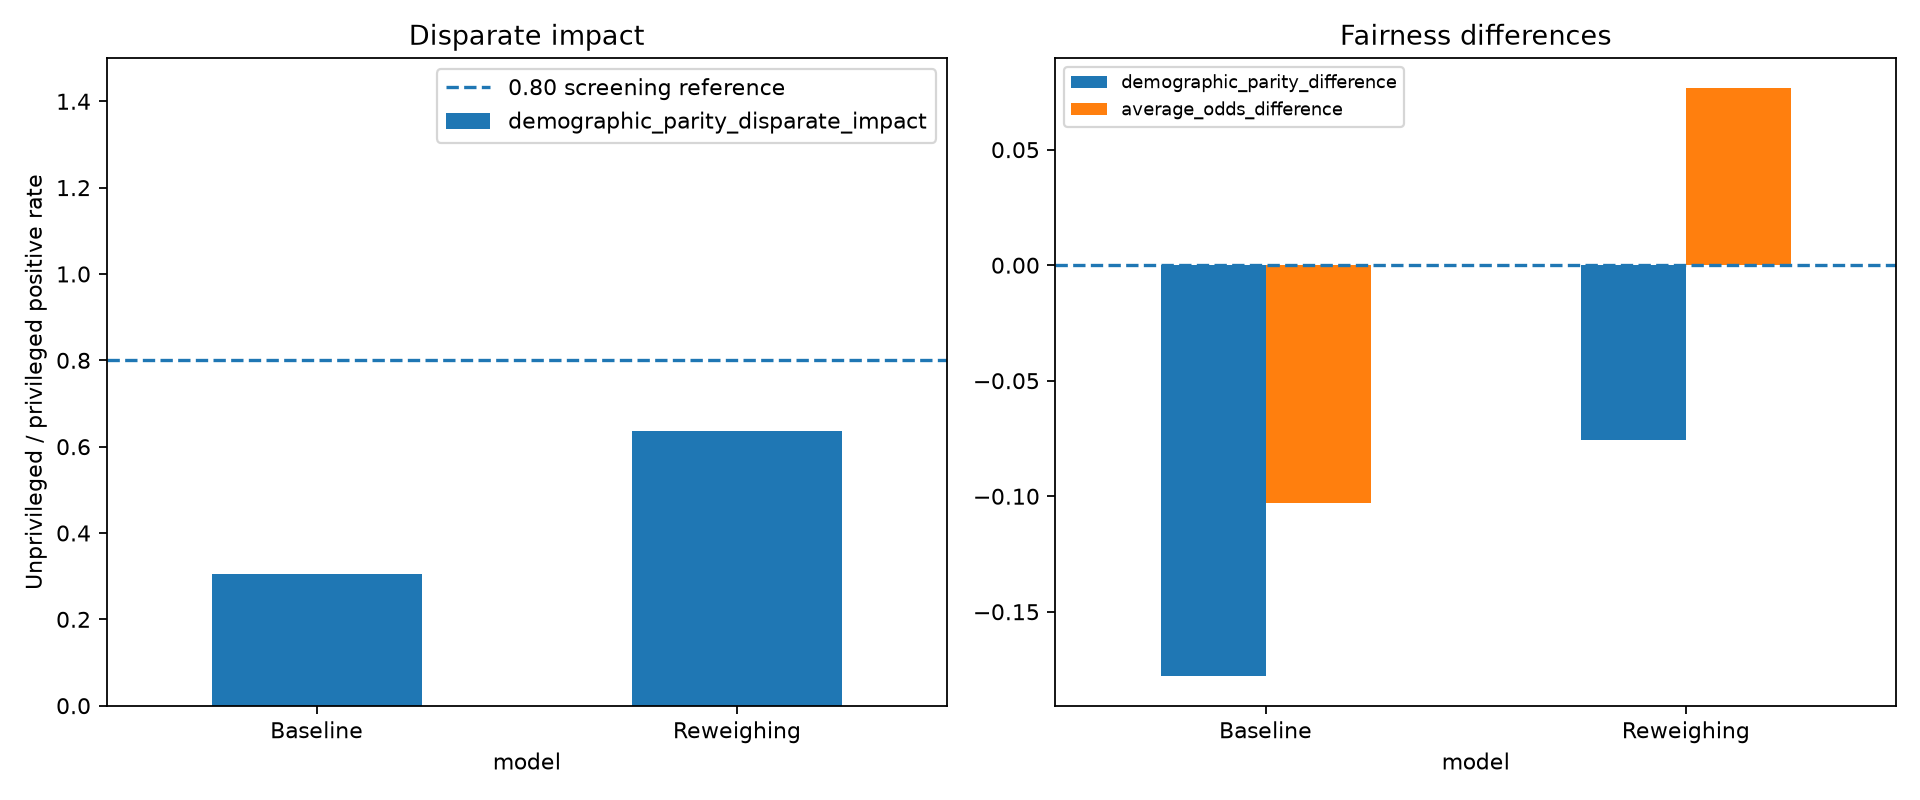

In [3]:
display(Image(filename=str(audit.OUTPUTS / 'fairness_comparison.png')))

### Interpretation

Compare the baseline and reweighed results rather than looking at one metric alone. Reweighing may improve one fairness measure while leaving other disparities. Accuracy and fairness must both be considered, and results depend on dataset quality, the chosen groups, and the model.

## 3. SHAP explanation for the W4D1 model

This separate experiment uses the synthetic classification dataset from W4D1. SHAP values describe how features contribute to this fitted model's predictions; they do not establish causation or real-world fairness.


W4D1 SHAP demonstration:
{
  "model": "StandardScaler + LogisticRegression",
  "dataset": "Synthetic make_classification dataset used by W4D1",
  "train_samples": 1200,
  "test_samples": 300,
  "accuracy_on_this_split": 0.8066666666666666,
  "features": 20,
  "shap_background_samples": 100,
  "shap_explained_samples": 200,
  "interpretation": "SHAP values explain the fitted model on synthetic data. They do not establish causation or real-world validity."
}
Saved SHAP summary plot and metrics.


,value
model,StandardScaler + LogisticRegression
dataset,Synthetic make_classification dataset used by ...
train_samples,1200
test_samples,300
accuracy_on_this_split,0.806667
features,20
shap_background_samples,100
shap_explained_samples,200
interpretation,SHAP values explain the fitted model on synthe...


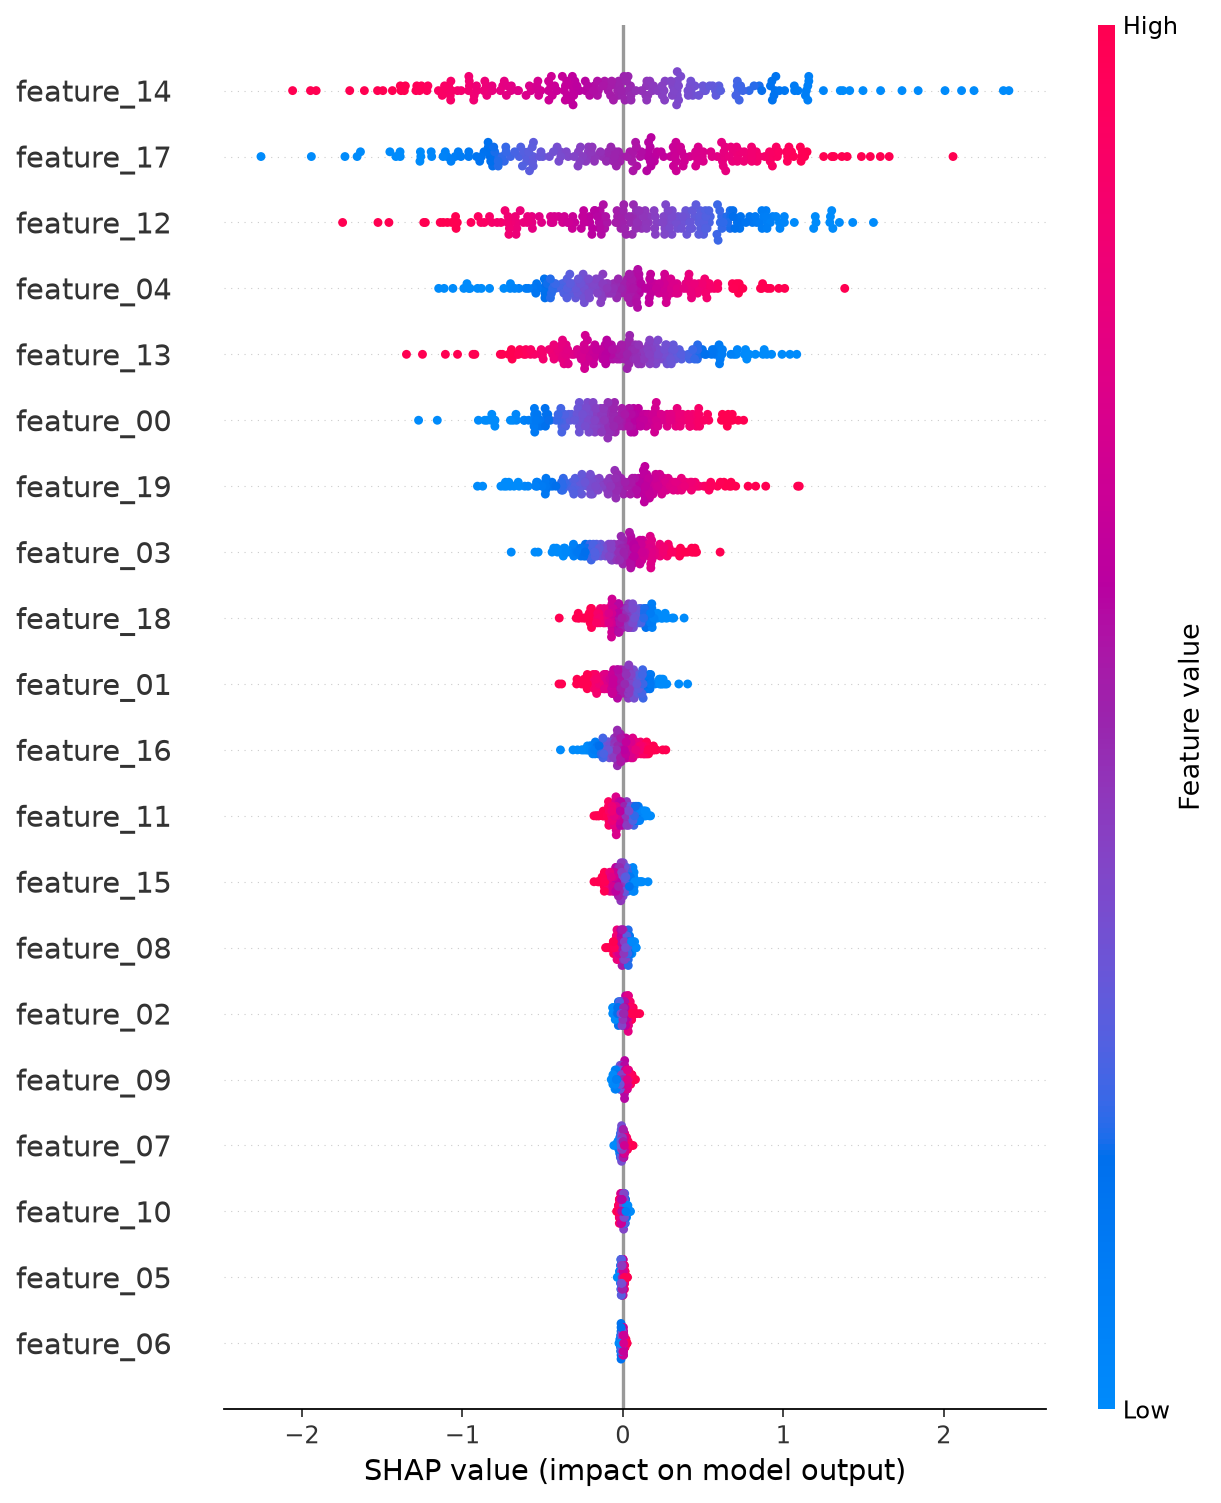

In [4]:
shap_results = audit.explain_w4d1_model()
display(pd.Series(shap_results, name='value').to_frame())
display(Image(filename=str(audit.OUTPUTS / 'shap_summary.png')))

## 4. Limitations and responsible use

- The Adult Income dataset has missing values that AIF360 may remove.
- Results are specific to this split, preprocessing, model, and group definitions.
- Reweighing does not guarantee fairness across every metric or intersectional group.
- SHAP explanations do not prove that a feature causes an outcome.
- Neither experiment justifies deploying a model in a high-impact setting without further validation.